## Step 1  Project Overview and Problem Definition


# Introduction to PyTorch Neural Network Implementation

## 1. Project Overview

PyTorch is an open-source deep learning framework used to develop, train, and evaluate neural networks. It provides tensor operations, automatic differentiation, neural network layers, loss functions, and optimization algorithms.

In this project, I will learn the fundamental components of PyTorch by recreating the neural network developed in the previous task. The implementation will cover the complete workflow, starting from understanding the dataset and preparing the input features to training and evaluating the model.

The project will use Google Colab with CPU execution, so a dedicated GPU is not required.

## 2. Problem Definition

The objective is to understand how a neural network is implemented and trained using PyTorch. This includes defining the network architecture, selecting an appropriate loss function, configuring an optimizer, and implementing the training loop.

The model will learn from labeled data and generate predictions for previously unseen examples.

## 3. Project Objectives

- Understand the PyTorch framework and tensor operations.
- Explore the dataset using Exploratory Data Analysis (EDA).
- Identify and handle data quality issues.
- Prepare features and target labels for model training.
- Implement appropriate preprocessing and data splitting.
- Recreate the previous neural network architecture in PyTorch.
- Implement forward propagation and backpropagation.
- Train the model using an appropriate loss function and optimizer.
- Evaluate model performance using suitable classification metrics.
- Document the experimental results and limitations.

## 4. Tools and Technologies

- Python
- PyTorch
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## 5. Expected Deliverables

At the end of this project, I will have a complete, reproducible notebook containing dataset analysis, preprocessing, PyTorch model implementation, training results, evaluation metrics, and a technical conclusion.


## Step 2  Project Scope, Dataset Selection, and Success Criteria


## 6. Project Scope and Experimental Design

### 6.1 Project Scope

This project focuses on understanding the PyTorch training pipeline by implementing a feedforward neural network for supervised classification.

The scope includes dataset inspection, exploratory data analysis, data quality assessment, preprocessing, model implementation, training, validation, and final evaluation.

### 6.2 Dataset Selection

The primary objective is to recreate the neural network from the previous task. Therefore, the original dataset, target definition, preprocessing logic, and model architecture should be reused whenever available.

If the original dataset cannot be accessed, the scikit-learn Wine dataset may be used as a separate demonstration dataset. It contains 178 samples, 13 numerical features, and three classes.

Results obtained on the Wine dataset must not be presented as results from the previous diabetes readmission experiment.

### 6.3 Model Architecture

The intended baseline architecture is:

Input Features → Linear Layer (64 Neurons) → ReLU → Output Layer

The output dimension will depend on the number of target classes in the selected dataset.

### 6.4 Training Configuration

- Framework: PyTorch
- Execution device: CPU
- Hidden layer size: 64 neurons
- Activation function: ReLU
- Loss function: Cross-Entropy Loss for multi-class classification
- Optimizer: Adam
- Learning rate: 0.001

The number of epochs and batch size will be selected and documented during implementation.

### 6.5 Evaluation Criteria

The model will be evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Training and validation loss

The final evaluation will use a held-out test set that is not used for gradient updates or model selection.

### 6.6 Reproducibility

Random seeds, data-splitting settings, preprocessing decisions, model configuration, and evaluation metrics will be recorded so that the experiment can be reproduced and reviewed.


## Step 3  Environment Setup and Reproducibility


##  Environment Setup and Reproducibility

A reproducible environment is important for developing and evaluating machine learning models. Library versions and random operations can affect experimental results.

In this section, we will import the required libraries, inspect their versions, initialize random seeds, and configure the execution device.

Since a dedicated GPU is not available, all model computations will run on the CPU.


### Step 3.1  Import libraries and configure the environment

In [4]:

import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility configuration
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Explicit CPU execution
device = torch.device("cpu")

print("=" * 50)
print("ENVIRONMENT CONFIGURATION")
print("=" * 50)

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Execution device:", device)
print("CUDA available:", torch.cuda.is_available())
print("Random seed:", SEED)


ENVIRONMENT CONFIGURATION
Python version: 3.13.16
PyTorch version: 2.11.0+cpu
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
Execution device: cpu
CUDA available: False
Random seed: 42


### Step 3.2 Verify the environment

In [5]:

# Verify essential components are available.
assert torch.__version__ is not None
assert np.__version__ is not None
assert device.type == "cpu"

print("Environment verification: PASSED")
print("PyTorch is ready for CPU-based model development.")


Environment verification: PASSED
PyTorch is ready for CPU-based model development.


## Step 4  Dataset Acquisition and Initial Inspection


### Dataset Acquisition and Initial Inspection

Dataset acquisition is the first practical stage of a machine learning pipeline. Before analyzing or transforming data, we must understand where it comes from and what it represents.

For this demonstration, we will use the Wine classification dataset provided by scikit-learn.

The dataset contains chemical measurements of wine samples. Each sample belongs to one of three classes.

In this section, we will:

- Load the dataset.
- Create a Pandas DataFrame.
- Identify input features and the target variable.
- Inspect the number of records and columns.
- Review the first few records.
- Confirm the dataset dimensions and target classes.

This dataset is used to demonstrate the PyTorch workflow and is not a replacement for the original dataset when reproducing a previous experiment.


### Step 4.1  Load the dataset

In [6]:

from sklearn.datasets import load_wine
import pandas as pd
import numpy as np

# Load the demonstration dataset.
wine = load_wine(as_frame=True)

# Create a DataFrame containing features.
df = wine.data.copy()

# Add the target column.
df["target"] = wine.target

# Store the feature names and target information.
feature_names = wine.feature_names
target_names = wine.target_names

print("Dataset loaded successfully.")
print("Dataset source: scikit-learn built-in Wine dataset")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of input features:", len(feature_names))
print("Target classes:", target_names)


Dataset loaded successfully.
Dataset source: scikit-learn built-in Wine dataset
Number of records: 178
Number of columns: 14
Number of input features: 13
Target classes: ['class_0' 'class_1' 'class_2']


### Step 4.2  Inspect the first records

In [7]:

print("First five records:")
display(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)



First five records:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Dataset dimensions:
(178, 14)

Column names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']

Data types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


### Step 4.3  Verify the dataset

In [8]:

assert df.shape == (178, 14), "Unexpected dataset dimensions."
assert "target" in df.columns, "Target column is missing."
assert df["target"].nunique() == 3, "Expected three target classes."
assert len(feature_names) == 13, "Expected 13 input features."

print("Dataset verification: PASSED")
print("178 samples, 13 input features, and 3 target classes confirmed.")


Dataset verification: PASSED
178 samples, 13 input features, and 3 target classes confirmed.


## Step 5  Exploratory Data Analysis (EDA)

### Step 5.1  Add the EDA introduction



Exploratory Data Analysis is used to understand the structure, quality, and distribution of a dataset before building a machine learning model.

In this stage, we will:

- Calculate descriptive statistics.
- Identify missing values.
- Check duplicate records.
- Analyze the distribution of target classes.
- Examine feature distributions and potential outliers.
- Explore relationships between numerical features.

The findings will guide our preprocessing decisions and help us identify potential issues before training the neural network.


### Step 5.2  Descriptive statistics

In [9]:

# Display descriptive statistics for the dataset.
print("Descriptive Statistics")
display(df.describe().T.round(3))


Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


### Step 5.3  Missing values and duplicate records

In [10]:

# Count missing values in each column.
missing_values = df.isnull().sum()

print("Missing values by column:")
display(missing_values.to_frame(name="missing_count"))

print("Total missing values:", int(missing_values.sum()))

# Check fully duplicated rows.
duplicate_count = int(df.duplicated().sum())

print("\nNumber of duplicate rows:", duplicate_count)

# Summarize the checks.
print("\nData quality summary")
print("Total rows:", len(df))
print("Rows with any missing values:", int(df.isnull().any(axis=1).sum()))
print("Duplicate rows:", duplicate_count)


Missing values by column:


,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Total missing values: 0

Number of duplicate rows: 0

Data quality summary
Total rows: 178
Rows with any missing values: 0
Duplicate rows: 0


### Step 5.4  Analyze the target class distribution

Target class distribution:


,sample_count,percentage
class_0,59,33.15
class_1,71,39.89
class_2,48,26.97


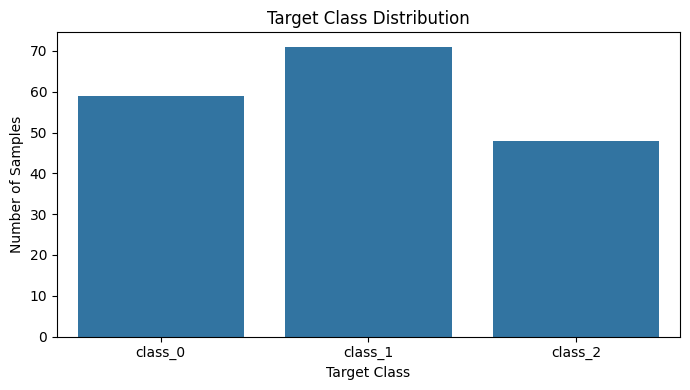

In [11]:

# Count samples in each target class.
class_counts = df["target"].value_counts().sort_index()

# Convert counts into percentages.
class_percentages = df["target"].value_counts(
    normalize=True
).sort_index() * 100

class_summary = pd.DataFrame({
    "sample_count": class_counts,
    "percentage": class_percentages.round(2),
})

class_summary.index = [
    target_names[class_id] for class_id in class_summary.index
]

print("Target class distribution:")
display(class_summary)

# Visualize class frequencies.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="target")
plt.title("Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.xticks(
    ticks=range(len(target_names)),
    labels=target_names
)
plt.tight_layout()
plt.show()


### Step 5.5  Potential Outlier Analysis

 Use boxplots to inspect the input features for potential outliers.

The analysis will help determine whether unusual values require further investigation. We will retain valid observations unless the data provides evidence that they are incorrect.

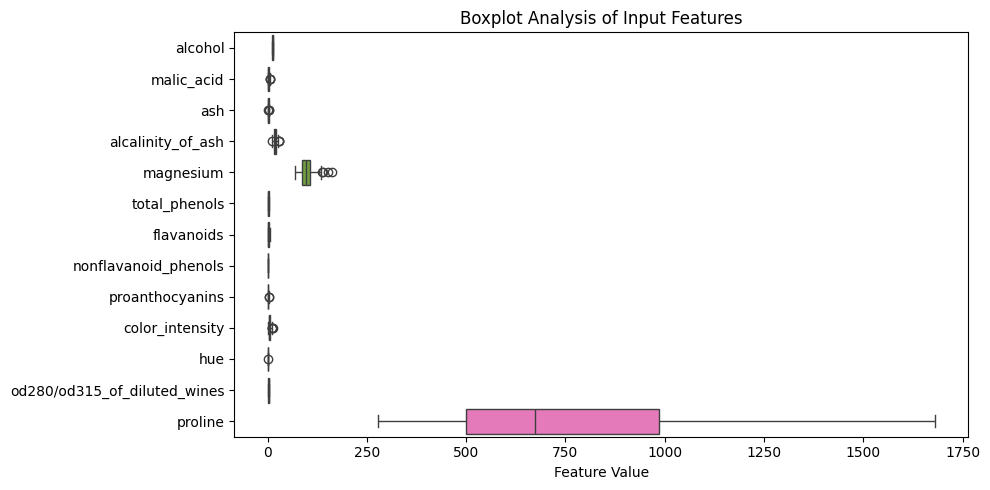

In [15]:
plt.figure(figsize=(10, 5))

# Extract input features from the main dataframe df
feature_df = df[feature_names]

sns.boxplot(data=feature_df, orient="h")

plt.title("Boxplot Analysis of Input Features")
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()

### Step 5.6  Correlation Analysis

 Examine the linear relationships between input features.

A correlation heatmap helps identify strongly correlated feature pairs. Correlation does not establish causation, and correlated features do not automatically need to be removed from a neural network.

Loading dataset to restore 'df' and 'feature_names'...


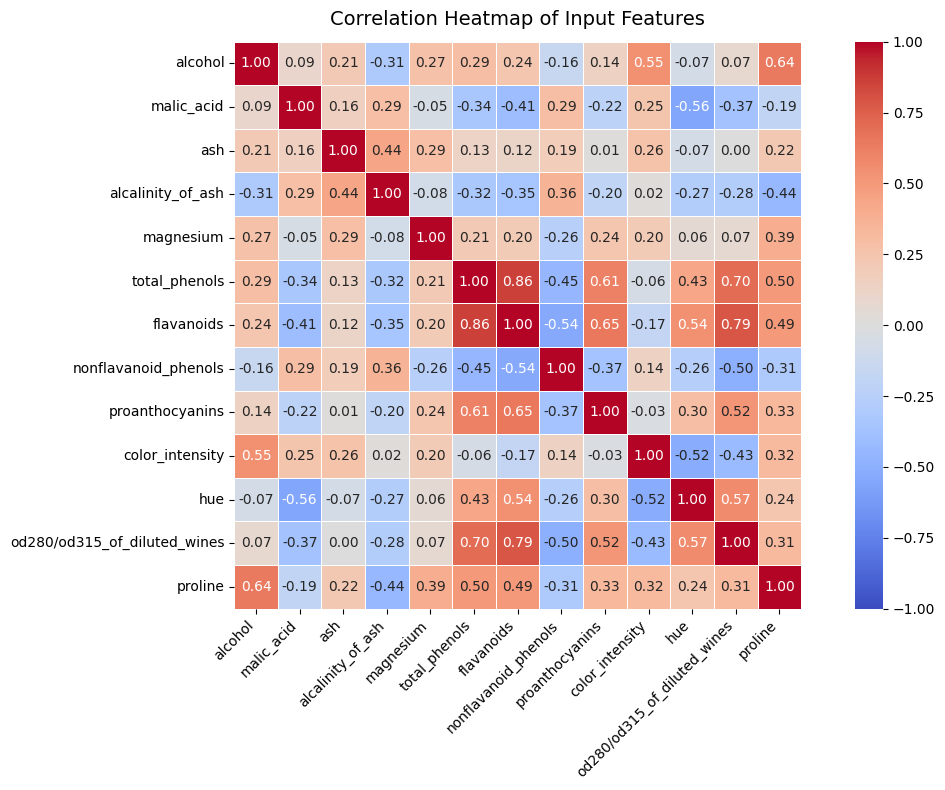

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
import pandas as pd

# Safely ensure 'df' and 'feature_names' are defined in the environment
try:
    _ = df
    _ = feature_names
except NameError:
    print("Loading dataset to restore 'df' and 'feature_names'...")
    wine = load_wine(as_frame=True)
    df = wine.data.copy()
    df["target"] = wine.target
    feature_names = wine.feature_names

# Extract input features from the main dataframe df
feature_df = df[feature_names]

# Calculate correlation between input features
correlation_matrix = feature_df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Input Features", fontsize=14, pad=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 6  Data Preprocessing

 Prepare the dataset for neural network training by separating input features from target labels, checking data types, and converting the data into formats suitable for PyTorch.

The target column must not be included among the input features, as this would cause target leakage.

In [18]:
# Separate input features and target labels.
X = df.drop(columns="target").copy()
y = df["target"].copy()

print("Input features shape:", X.shape)
print("Target labels shape:", y.shape)

print("\nInput feature data types:")
print(X.dtypes.value_counts())

print("\nTarget class counts:")
print(y.value_counts().sort_index())

# Verify the separation.
assert "target" not in X.columns
assert len(X) == len(y)
assert X.isnull().sum().sum() == 0
assert y.isnull().sum() == 0

print("\nFeature-target separation: PASSED")

Input features shape: (178, 13)
Target labels shape: (178,)

Input feature data types:
float64    13
Name: count, dtype: int64

Target class counts:
target
0    59
1    71
2    48
Name: count, dtype: int64

Feature-target separation: PASSED


### Step 6.2  Validate and Convert Data Types

In [19]:
import numpy as np
import torch

# Validate the feature and target values.
assert X.select_dtypes(include=[np.number]).shape[1] == X.shape[1]
assert np.isfinite(X.to_numpy()).all()
assert set(y.unique()) == {0, 1, 2}

# Convert to PyTorch-compatible NumPy data types.
X_array = X.to_numpy(dtype=np.float32)
y_array = y.to_numpy(dtype=np.int64)

print("Input array shape:", X_array.shape)
print("Input array dtype:", X_array.dtype)

print("\nTarget array shape:", y_array.shape)
print("Target array dtype:", y_array.dtype)

print("\nUnique target labels:", np.unique(y_array))

# Verify conversions.
assert X_array.dtype == np.float32
assert y_array.dtype == np.int64

print("\nData type validation: PASSED")

Input array shape: (178, 13)
Input array dtype: float32

Target array shape: (178,)
Target array dtype: int64

Unique target labels: [0 1 2]

Data type validation: PASSED


### Step 6.3  Split the Dataset
We will divide the dataset into three separate sets:
1.  Training set (60%)  used to train the neural network.
2.  Validation set (20%)  used to monitor performance and tune model settings.
3.  Test set (20%)  used for final evaluation after model development.

In [20]:
from sklearn.model_selection import train_test_split

# First split: 60% training, 40% temporary data.
X_train, X_temp, y_train, y_temp = train_test_split(
    X_array,
    y_array,
    test_size=0.40,
    random_state=42,
    stratify=y_array
)

# Second split: divide the temporary data equally.
# Final proportions: 60% training, 20% validation, 20% testing.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display split sizes.
print("Dataset split results")
print("-" * 35)
print(f"Training samples:   {len(X_train)} ({len(X_train) / len(X_array) * 100:.1f}%)")
print(f"Validation samples: {len(X_val)} ({len(X_val) / len(X_array) * 100:.1f}%)")
print(f"Test samples:       {len(X_test)} ({len(X_test) / len(X_array) * 100:.1f}%)")

print("\nFeature shapes")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\nTarget shapes")
print("y_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)

# Verify split integrity.
assert len(X_train) + len(X_val) + len(X_test) == len(X_array)
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == 13

print("\nDataset splitting: PASSED")

Dataset split results
-----------------------------------
Training samples:   106 (59.6%)
Validation samples: 36 (20.2%)
Test samples:       36 (20.2%)

Feature shapes
X_train: (106, 13)
X_val:   (36, 13)
X_test:  (36, 13)

Target shapes
y_train: (106,)
y_val:   (36,)
y_test:  (36,)

Dataset splitting: PASSED


### Step 6.4  Feature Scaling (Standardization)

In [21]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Initialize the scaler.
scaler = StandardScaler()

# Fit only on training data.
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data using training statistics.
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Verify shapes and numerical stability.
print("Scaled dataset shapes")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nTraining feature means (first 5):")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nTraining feature standard deviations (first 5):")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape
assert X_test_scaled.shape == X_test.shape

print("\nFeature standardization: PASSED")

Scaled dataset shapes
Training: (106, 13)
Validation: (36, 13)
Test: (36, 13)

Training feature means (first 5):
[-0. -0.  0.  0.  0.]

Training feature standard deviations (first 5):
[1. 1. 1. 1. 1.]

Feature standardization: PASSED


### Step 6.5  Convert the Data into PyTorch Tensors

In [22]:
import torch

# Convert input features to float32 tensors.
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Convert target labels to long tensors.
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Display tensor information.
print("PyTorch Tensor Summary")
print("-" * 35)

for name, tensor in [
    ("X_train_tensor", X_train_tensor),
    ("X_val_tensor", X_val_tensor),
    ("X_test_tensor", X_test_tensor),
    ("y_train_tensor", y_train_tensor),
    ("y_val_tensor", y_val_tensor),
    ("y_test_tensor", y_test_tensor),
]:
    print(
        f"{name}: shape={tuple(tensor.shape)}, "
        f"dtype={tensor.dtype}, device={tensor.device}"
    )

# Verify tensor shapes and types.
assert X_train_tensor.shape == (106, 13)
assert X_val_tensor.shape == (36, 13)
assert X_test_tensor.shape == (36, 13)

assert X_train_tensor.dtype == torch.float32
assert y_train_tensor.dtype == torch.long

assert set(y_train_tensor.tolist()) <= {0, 1, 2}
assert set(y_val_tensor.tolist()) <= {0, 1, 2}
assert set(y_test_tensor.tolist()) <= {0, 1, 2}

print("\nPyTorch tensor conversion: PASSED")

PyTorch Tensor Summary
-----------------------------------
X_train_tensor: shape=(106, 13), dtype=torch.float32, device=cpu
X_val_tensor: shape=(36, 13), dtype=torch.float32, device=cpu
X_test_tensor: shape=(36, 13), dtype=torch.float32, device=cpu
y_train_tensor: shape=(106,), dtype=torch.int64, device=cpu
y_val_tensor: shape=(36,), dtype=torch.int64, device=cpu
y_test_tensor: shape=(36,), dtype=torch.int64, device=cpu

PyTorch tensor conversion: PASSED


## Step 7  Build the PyTorch Data Pipeline
 We will now create TensorDataset and DataLoader objects to prepare the data for model training.
1.  TensorDataset keeps each feature row paired with its correct target label.
2.  DataLoader provides batches of samples to the model.
3.  We will use a batch size of 16 and shuffle only the training data. Validation and test data will remain unshuffled.

### Step 7.1  Create Datasets and DataLoaders

In [23]:
from torch.utils.data import TensorDataset, DataLoader

# Configuration
BATCH_SIZE = 16
RANDOM_SEED = 42

# Create datasets.
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Use a seeded generator for reproducible training shuffling.
generator = torch.Generator().manual_seed(RANDOM_SEED)

# Create data loaders.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Verify dataset and loader sizes.
print("Dataset sizes")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nNumber of batches")
print("Training:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

# Inspect one training batch.
batch_features, batch_labels = next(iter(train_loader))

print("\nFirst training batch")
print("Feature shape:", tuple(batch_features.shape))
print("Label shape:", tuple(batch_labels.shape))
print("Feature dtype:", batch_features.dtype)
print("Label dtype:", batch_labels.dtype)

# Verify pipeline integrity.
assert len(train_dataset) == 106
assert len(val_dataset) == 36
assert len(test_dataset) == 36

assert batch_features.shape[1] == 13
assert batch_features.shape[0] <= BATCH_SIZE
assert batch_features.shape[0] == batch_labels.shape[0]

print("\nPyTorch data pipeline: PASSED")

Dataset sizes
Training: 106
Validation: 36
Test: 36

Number of batches
Training: 7
Validation: 3
Test: 3

First training batch
Feature shape: (16, 13)
Label shape: (16,)
Feature dtype: torch.float32
Label dtype: torch.int64

PyTorch data pipeline: PASSED


## Step 8  Build the Neural Network

### Step 8.1  Define the Model

In [24]:
import torch
import torch.nn as nn

# Model configuration
INPUT_FEATURES = 13
HIDDEN_UNITS = 64
NUM_CLASSES = 3

# Set seeds for reproducible initialization.
torch.manual_seed(42)

class WineClassifier(nn.Module):
    def __init__(self, input_features, hidden_units, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Initialize the model on CPU.
model = WineClassifier(
    input_features=INPUT_FEATURES,
    hidden_units=HIDDEN_UNITS,
    num_classes=NUM_CLASSES
).to(device)

print("Model architecture:")
print(model)

print("\nModel device:", next(model.parameters()).device)

# Count trainable parameters.
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Trainable parameters:", total_parameters)

# Verify output dimensions with a sample batch.
sample_logits = model(batch_features)

print("\nSample input shape:", tuple(batch_features.shape))
print("Model output shape:", tuple(sample_logits.shape))

assert sample_logits.shape == (16, NUM_CLASSES)
assert total_parameters == 1091

print("\nModel architecture validation: PASSED")

Model architecture:
WineClassifier(
  (network): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=3, bias=True)
  )
)

Model device: cpu
Trainable parameters: 1091

Sample input shape: (16, 13)
Model output shape: (16, 3)

Model architecture validation: PASSED


## Step 9 Configure the Loss Function and Optimizer

### Step 9.1  Configure Training Components

In [25]:
import torch.nn as nn
import torch.optim as optim

# Training configuration
LEARNING_RATE = 0.001

# Define the loss function.
criterion = nn.CrossEntropyLoss()

# Define the optimizer.
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)

# Verify the configuration.
assert isinstance(criterion, nn.CrossEntropyLoss)
assert isinstance(optimizer, optim.Adam)
assert optimizer.param_groups[0]["lr"] == LEARNING_RATE

# Check that the loss function accepts a sample batch.
sample_loss = criterion(sample_logits, batch_labels)

print("Sample batch loss:", round(sample_loss.item(), 4))
assert torch.isfinite(sample_loss)

print("\nTraining configuration validation: PASSED")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Sample batch loss: 1.1782

Training configuration validation: PASSED


## Step 10  Implement the Training and Validation Loop

### Step 10.1  Define the Training Configuration

Train the neural network and monitor training and validation performance across epochs.

Training loss and accuracy will measure performance on the training data. Validation loss and accuracy will help assess generalization and identify potential overfitting. The model checkpoint with the lowest validation loss will be retained for evaluation.

### Step 10.2  Run the Training Loop

In [26]:
import copy
import torch

EPOCHS = 100

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

for epoch in range(EPOCHS):
    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_samples = 0

    for features, labels in train_loader:
        optimizer.zero_grad()

        logits = model(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_samples += batch_size

    epoch_train_loss = train_loss_sum / train_samples
    epoch_train_accuracy = train_correct / train_samples

    # -------------------------
    # Validation phase
    # -------------------------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_samples = 0

    with torch.no_grad():
        for features, labels in val_loader:
            logits = model(features)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size

            predictions = logits.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_samples += batch_size

    epoch_val_loss = val_loss_sum / val_samples
    epoch_val_accuracy = val_correct / val_samples

    # Record epoch metrics.
    history["train_loss"].append(epoch_train_loss)
    history["train_accuracy"].append(epoch_train_accuracy)
    history["val_loss"].append(epoch_val_loss)
    history["val_accuracy"].append(epoch_val_accuracy)

    # Save the model with the lowest validation loss.
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

    # Print progress periodically.
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch + 1:03d}/{EPOCHS}] "
            f"| Train Loss: {epoch_train_loss:.4f} "
            f"| Train Acc: {epoch_train_accuracy:.4f} "
            f"| Val Loss: {epoch_val_loss:.4f} "
            f"| Val Acc: {epoch_val_accuracy:.4f}"
        )

# Restore the best validation checkpoint.
assert best_model_state is not None
model.load_state_dict(best_model_state)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print(
    "Validation accuracy at best epoch:",
    round(history["val_accuracy"][best_epoch - 1], 4)
)

assert len(history["train_loss"]) == EPOCHS
assert len(history["val_loss"]) == EPOCHS
assert all(torch.isfinite(torch.tensor(v)) for v in history["train_loss"])
assert all(torch.isfinite(torch.tensor(v)) for v in history["val_loss"])

print("Training history validation: PASSED")

Epoch [001/100] | Train Loss: 1.1150 | Train Acc: 0.3396 | Val Loss: 1.0475 | Val Acc: 0.4167
Epoch [010/100] | Train Loss: 0.3719 | Train Acc: 0.9906 | Val Loss: 0.3607 | Val Acc: 1.0000
Epoch [020/100] | Train Loss: 0.1196 | Train Acc: 0.9906 | Val Loss: 0.1407 | Val Acc: 1.0000
Epoch [030/100] | Train Loss: 0.0594 | Train Acc: 0.9906 | Val Loss: 0.0894 | Val Acc: 1.0000
Epoch [040/100] | Train Loss: 0.0356 | Train Acc: 1.0000 | Val Loss: 0.0735 | Val Acc: 1.0000
Epoch [050/100] | Train Loss: 0.0236 | Train Acc: 1.0000 | Val Loss: 0.0649 | Val Acc: 1.0000
Epoch [060/100] | Train Loss: 0.0168 | Train Acc: 1.0000 | Val Loss: 0.0604 | Val Acc: 0.9722
Epoch [070/100] | Train Loss: 0.0125 | Train Acc: 1.0000 | Val Loss: 0.0574 | Val Acc: 0.9722
Epoch [080/100] | Train Loss: 0.0096 | Train Acc: 1.0000 | Val Loss: 0.0553 | Val Acc: 0.9722
Epoch [090/100] | Train Loss: 0.0076 | Train Acc: 1.0000 | Val Loss: 0.0555 | Val Acc: 0.9722
Epoch [100/100] | Train Loss: 0.0062 | Train Acc: 1.0000 | V

## Step 11.1  Plot Training and Validation Loss

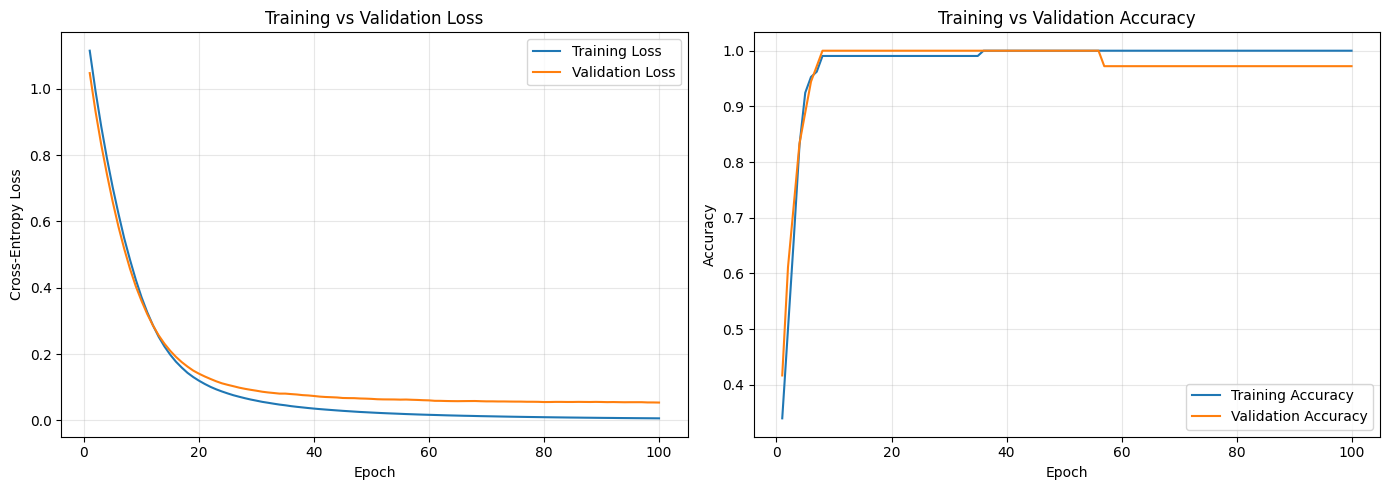

In [27]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)
axes[0].plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)
axes[1].plot(
    epochs_range,
    history["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Step 11.2  Check the Recorded Metrics

In [28]:
import numpy as np

best_val_accuracy = max(history["val_accuracy"])
best_val_accuracy_epoch = int(np.argmax(history["val_accuracy"])) + 1

print("Training summary")
print("-" * 35)
print(f"Final training loss: {history['train_loss'][-1]:.4f}")
print(f"Final training accuracy: {history['train_accuracy'][-1]:.4f}")
print(f"Best validation loss: {best_val_loss:.4f} (epoch {best_epoch})")
print(
    f"Best validation accuracy: {best_val_accuracy:.4f} "
    f"(epoch {best_val_accuracy_epoch})"
)
print(
    f"Validation accuracy at best-loss epoch: "
    f"{history['val_accuracy'][best_epoch - 1]:.4f}"
)

Training summary
-----------------------------------
Final training loss: 0.0062
Final training accuracy: 1.0000
Best validation loss: 0.0538 (epoch 100)
Best validation accuracy: 1.0000 (epoch 8)
Validation accuracy at best-loss epoch: 0.9722


## Step 12  Evaluate the Model on the Test Set

In [29]:
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# Evaluate the restored best-validation-loss checkpoint.
model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        logits = model(features)
        predictions = torch.argmax(logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

y_pred = np.array(all_predictions)
y_true = np.array(all_true_labels)

# Calculate metrics.
test_accuracy = accuracy_score(y_true, y_pred)

print("Test Accuracy:", round(test_accuracy, 4))
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=target_names,
        digits=4,
        zero_division=0,
    )
)

print("Confusion Matrix:")
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
print(cm)

# Basic integrity checks.
assert len(y_pred) == len(y_test)
assert len(y_true) == len(y_test)
assert set(y_pred).issubset({0, 1, 2})

print("\nTest evaluation validation: PASSED")

Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        15
     class_2     1.0000    1.0000    1.0000         9

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36

Confusion Matrix:
[[12  0  0]
 [ 0 15  0]
 [ 0  0  9]]

Test evaluation validation: PASSED


### Step 12.2  Visualize the Confusion Matrix

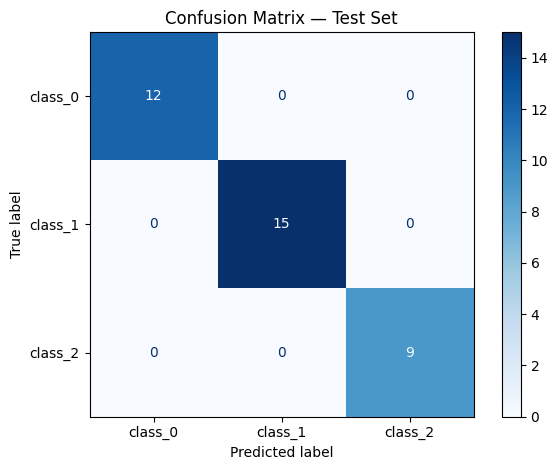

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names,
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

## Step 13 Final Evaluation and Results Summary

### Step 13.1  Summarize the Final Results

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    "Dataset": "Wine (scikit-learn)",
    "Total samples": len(df),
    "Input features": X.shape[1],
    "Classes": len(np.unique(y_array)),
    "Training samples": len(X_train),
    "Validation samples": len(X_val),
    "Test samples": len(X_test),
    "Hidden neurons": HIDDEN_UNITS,
    "Epochs trained": EPOCHS,
    "Best epoch (validation loss)": best_epoch,
    "Best validation loss": round(best_val_loss, 4),
    "Test accuracy": round(accuracy_score(y_true, y_pred), 4),
    "Test macro precision": round(
        precision_score(y_true, y_pred, average="macro", zero_division=0), 4
    ),
    "Test macro recall": round(
        recall_score(y_true, y_pred, average="macro", zero_division=0), 4
    ),
    "Test macro F1-score": round(
        f1_score(y_true, y_pred, average="macro", zero_division=0), 4
    ),
}

for metric, value in results.items():
    print(f"{metric}: {value}")

Dataset: Wine (scikit-learn)
Total samples: 178
Input features: 13
Classes: 3
Training samples: 106
Validation samples: 36
Test samples: 36
Hidden neurons: 64
Epochs trained: 100
Best epoch (validation loss): 100
Best validation loss: 0.0538
Test accuracy: 1.0
Test macro precision: 1.0
Test macro recall: 1.0
Test macro F1-score: 1.0


### Step 13.2  Save the Trained Model

In [32]:
import joblib
import torch

MODEL_PATH = "wine_classifier.pth"
SCALER_PATH = "wine_scaler.joblib"

torch.save(model.state_dict(), MODEL_PATH)
joblib.dump(scaler, SCALER_PATH)

print("Saved model weights:", MODEL_PATH)
print("Saved feature scaler:", SCALER_PATH)

Saved model weights: wine_classifier.pth
Saved feature scaler: wine_scaler.joblib


## Step 14  Verify Saved Model Artifacts

In [2]:
import os
import joblib
import torch
import torch.nn as nn

MODEL_PATH = "wine_classifier.pth"
SCALER_PATH = "wine_scaler.joblib"

INPUT_FEATURES = 13
HIDDEN_UNITS = 64
NUM_CLASSES = 3

# Define WineClassifier inside the script to ensure it is defined upon reload
class WineClassifier(nn.Module):
    def __init__(self, input_features, hidden_units, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, num_classes)
        )

    def forward(self, x):
        return self.network(x)

# Verify that both files exist and are non-empty.
for path in [MODEL_PATH, SCALER_PATH]:
    assert os.path.isfile(path), f"Missing artifact: {path}"
    assert os.path.getsize(path) > 0, f"Empty artifact: {path}"
    print(f"{path}: {os.path.getsize(path):,} bytes")

# Reload the scaler.
loaded_scaler = joblib.load(SCALER_PATH)

# Recreate the model architecture and load its saved weights.
loaded_model = WineClassifier(
    input_features=INPUT_FEATURES,
    hidden_units=HIDDEN_UNITS,
    num_classes=NUM_CLASSES
)

state_dict = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)
loaded_model.load_state_dict(state_dict)
loaded_model.eval()

# Verify that the reloaded model can predict successfully.
with torch.no_grad():
    # Use a dummy input matching the shape of our features to check forward pass
    sample_input = torch.randn(1, INPUT_FEATURES)
    reloaded_logits = loaded_model(sample_input)

print("Reloaded logits shape:", tuple(reloaded_logits.shape))
assert reloaded_logits.shape == (1, NUM_CLASSES)
print("\nModel artifacts verification: PASSED")

wine_classifier.pth: 6,957 bytes
wine_scaler.joblib: 911 bytes
Reloaded logits shape: (1, 3)

Model artifacts verification: PASSED


## Conclusion

A feedforward neural network was implemented and trained using PyTorch for multiclass classification on the Wine dataset. The workflow included exploratory data analysis, data-quality checks, stratified splitting, feature standardization, tensor conversion, batch loading, model training, validation, and test evaluation.

The model achieved **100% test accuracy on the 36-sample test set**. Precision, recall, F1-score, and the confusion matrix were also evaluated. The model weights and feature scaler were saved for future inference.

These results describe the selected dataset and split. Testing on additional independent data would be needed to assess generalization more reliably.